# Set partitioning: locality grid and training audit

This report describes a **new structural benchmark**, not completed optimization results. All 945 inputs were generated and validated locally. Existing optimization results are preserved. Their training implementation contained an indexing error, so they cannot establish the performance of the intended gradient-based method; rerun both arms with the corrected implementation before drawing conclusions.

## Gradient audit

For real amplitudes $\psi(x)$, $Z=\sum_x\psi(x)^2$, nonnegative target weights $p_t$, and $s=\sum_t p_t$, the normalized cross entropy is

$$L=s\log Z-2\sum_t p_t\log|\psi(x_t)|.$$

At a bond in mixed canonical form, merge its two cores into charge blocks $M_q$. The external environments are isometric, so $Z=\sum_q\|M_q\|_F^2$. With one-dimensional charge sectors, every sample follows one charge path. For its selected merged entry $(a_t,b_t)$, the external amplitude factors cancel in $\partial\log|\psi(x_t)|$:

$$\frac{\partial L}{\partial M_q[a,b]}=\frac{2sM_q[a,b]}{Z}-2\sum_{t:(q_t,a_t,b_t)=(q,a,b)}\frac{p_t}{M_q[a,b]}.$$

The denominator is the product of the two **old** scalar core entries. The code's analytical formula was correct for normalized weights. Its indexing was not: `SiteIndex.InvXindex[x][2]` is the physical degeneracy index **within a physical charge sector**. For nonzero columns of A it is always 1. Using this value to select `XboundsDict` therefore accumulated every likelihood term at the first row/column of a merged charge block, even when the sample required another entry. The fixed code caches the physical-value positions during core reshaping, including missing sectors and zero columns. Both sweep directions use this direct lookup, without searching physical-charge vectors for each training example.

On the original locality data (instance 1), 14,982 of 112,000 sample/bond likelihood terms at w=5 (13.4%) and 15,316 at w=18 (13.7%) selected a different entry from the old code. These are counts on the initial model, not weighted gradient magnitudes or estimates for every training iteration. Thus the defect is present on the actual benchmark, not only on toy examples.

Two other corrections: zero-column branches previously referenced undefined `left_shape`/`right_shape`; the shared lookup handles these cases too. `Loss` now includes $s\log Z$ and ignores zero-weight observations, making it valid for canonical MPS that are not normalized. The gradient normalization term also includes $s$ (unchanged for normalized weights).

Validation in `scripts/check_training_gradient.jl` exhaustively enumerates small feasible spaces, perturbs individual merged entries and computes the normalized loss from all amplitudes. It checks both sweep directions, nonuniform random cores, multiple constraints and zero columns; it also checks normalization identities, loss decrease for a small step, exact serial-sampling conditionals against the Born probabilities, RNG replay, and feasibility after training. Run the script for the current numerical error report. The corrected audit passed 583 assertions, with maximum finite-difference discrepancy below $3\times10^{-10}$; the old indexing gives discrepancies of order one.

`src/mps_core.jl`: collection/splitting and the canonical norm identities passed these tests; no change to that file was needed. After each gradient step, the SVD retains **one singular value per charge sector**, moves the singular value to the next center, and thus restores the canonical form. `MaxR` and `CutOff` do not tune this nondegenerate routine. This is a projected gradient step, not an exact two-site minimization; a fixed learning rate of 0.05 does not guarantee monotonic loss decrease after every step. The audit covers the real, sector-dimension-one path used by these experiments, not generic degenerate or complex MPS.

The optimizer never differentiates $f(x)$ itself: objective values determine normalized Boltzmann training weights. Consequently, replacing the nonlinear objective by a linear one isolates a change in optimization landscape and weights, not a different MPS differentiation formula. All previous experiments using the faulty training path, including assignment, need reassessment. Exact structural ranks, indicator storage estimates, and sampling benchmarks without training are not invalidated by this training bug.


## Dataset and uniform generator

Seven spans $w\in\{5,6,8,10,12,15,18\}$, three numbers of **equalities** $m\in\{18,19,20\}$, and three size parameters $n\in\{13,14,15\}$ define 63 groups. Each has 15 independently seeded objective/sample instances: **945 tasks, 135 per span**. There are $N=n^2$ binary variables (169, 196, 225), not 13–15 binary variables.

Each column of $A\in\{0,1\}^{m\times N}$ is a distinct tile containing 1–4 ordered elements, with $\max(t)-\min(t)+1\le w$, and $b=\mathbf 1_m$. All $m$ singleton tiles and all adjacent pairs are mandatory. The singleton columns contain an identity matrix, so all $m$ equality rows are linearly independent. The remaining $N-m$ tile counts are apportioned to sizes 2, 3, 4 by largest remainders in the original ratio 62:88:57. Optional tiles are drawn uniformly without replacement within each size. Columns are sorted by minimum element and lexicographic tile order, putting the singleton last within each minimum-element group. No column permutation is applied. Some small-span groups have identical constraint matrices because their catalogue is exhausted; their objectives and samples remain independently seeded.

For the exact sampler, let $C(S)$ count completions of the covered-element set $S$. Choose the first uncovered element $u$ and consider tiles $t$ containing $u$ and disjoint from $S$:

$$C(S)=\sum_{t\ni u,\ t\cap S=\varnothing}C(S\cup t),\qquad C(\{1,\ldots,m\})=1.$$

Choose a tile with probability $C(S\cup t)/C(S)$. Each exact cover has a unique path through this recursion and probability $1/C(\varnothing)$ by telescoping. Integer rejection sampling and BigInt counts avoid floating-point bias. Sampling is with replacement. Every input is checked against an independent column-frontier path counter, its initial 500 draws are replayed exactly, and another independent batch of 500 draws is checked for $Ax=b$. The small-case validation additionally enumerates every cover, verifies its probability using exact rational arithmetic, and compares the rank profile against numerical ranks of explicit indicator unfoldings.

Singleton-last ordering allows every retained prefix to finish using future singletons. Distinct prefix charges have disjoint suffix supports; each charge sector has rank one. Therefore the number of extendable frontier states equals the exact full-indicator unfolding rank. The sliding frontier retires covered elements after their singleton column. These ranks describe **full support**, not the model learned from the initial data. More solutions do not by themselves imply larger unfolding ranks.


## Experimental protocol and objectives

The same runner handles the old 280 inputs and the new 945 inputs. `--linear` or `--entropic` is mandatory. Both choices reuse exactly the same constraints, initial sample, linear coefficients and seeds. For each saved instance:

$$f_{\rm linear}(x)=\frac{c^Tx}{\sqrt m},\qquad f_{\rm entropic}(x)=\frac{c^Tx}{\sqrt m}+\tau\log\left[\frac1{32}\sum_{s=1}^{32}\exp\left(\frac{W_s^Tx}{\tau\sqrt m}\right)\right],\quad\tau=0.5.$$

The coefficients $c_j$ are uniform on $[-1,1)$; scenario entries are independent standard normals. Stable log-mean-exp evaluation is used. The linear objective removes only the risk term; it does not generate a different $c$.

* Initial data: 500 exact uniform draws shared within each pair. EELS removes duplicate columns as in the existing protocol; ADD retains its original handling.
* 15 global iterations, 5,000 MPS draws per iteration, one right-and-left training sweep, learning rate 0.05, one-dimensional charge sectors, elite fraction 0.05, no worst-sample retention.
* EELS uses gamma=1 and **no external draws after initialization**. Its baseline has the same restriction.
* ADD uses **Best Cost + GDF / best nonzero mixed**, filter weight 0.4, with 5,000 external uniform draws on each iteration. Its own BestCost baseline receives the identical external batch, verified by full-batch hashes. The EELS and ADD baselines are separate because their information budgets differ.
* Training weights are normalized exponentials using the standard deviation of current costs as temperature. The zero-variance case uses uniform weights.
* Each pair uses the same initial dataset and seeds, with alternating execution order. Runs are sequential within a job, Julia and BLAS have one thread, and a directory lock prevents concurrent writers. Atomic checkpoints contain source/input hashes and reject incompatible resumes.
* The incumbent is the best among **all evaluated candidates**, including the final external batch. Curves, feasible incumbents, paired initial hashes and paired external hashes are checked before saving.

Per objective: 1,120 solver runs on the old 280 tasks, or 3,780 on the new 945 tasks (two distinct baseline/strategy pairs per task). Optimization on the full benchmark is left to the cluster; only smoke checks run locally.

### Launch from the repository root

```bash
# Original 18-equality, n=15 dataset:
bash scripts/bash/run_PartitionLocality.sh --linear
bash scripts/bash/run_PartitionLocality.sh --entropic

# New 63-group grid:
bash scripts/bash/run_PartitionLocality.sh --grid --linear
bash scripts/bash/run_PartitionLocality.sh --grid --entropic
```

Use `bash` to invoke the self-submitting wrapper. It selects 7 Slurm jobs for the old dataset or 63 for the grid, at most four running concurrently, each with one CPU and 8 GB. The existing partition setting is retained. Copy the generated `data/set_partitioning/locality_grid_v1/instances/` directory to the cluster first. Missing inputs cause an error, never silent regeneration. A Julia environment with the project dependencies installed is required.

Results go to `data/set_partitioning/{locality_v1,locality_grid_v1}/results_gradient_v2/{linear,entropic}/`. Old `results/` files are preserved. Each grid result filename identifies span, equality count and n; dictionaries retain the usual nesting `res_dict["best_cost"][n][i]`, `res_dict["EELS"][n][i]`, or `res_dict["best nonzero mixed"][0.4][n][i]`. Separate files avoid collisions between groups with the same n and i. `diagnostics` includes timings, hashes and structural ranks. Do not pool old faulty-training results with the new version.


## Rank versus span

For each instance, maximum and mean ranks are computed over the **N−1 internal bonds**, excluding the two unit boundary ranks. Error bars show the **sample standard deviation (ddof=1) across all 135 instances at that span**. The vertical axes are logarithmic; error bars represent arithmetic mean plus/minus SD on the original rank scale. They include differences between m/n groups and within groups; they are not confidence intervals or standard errors. Every parameter combination has equal weight because all contain 15 tasks. Optimization is not used to obtain these ranks.


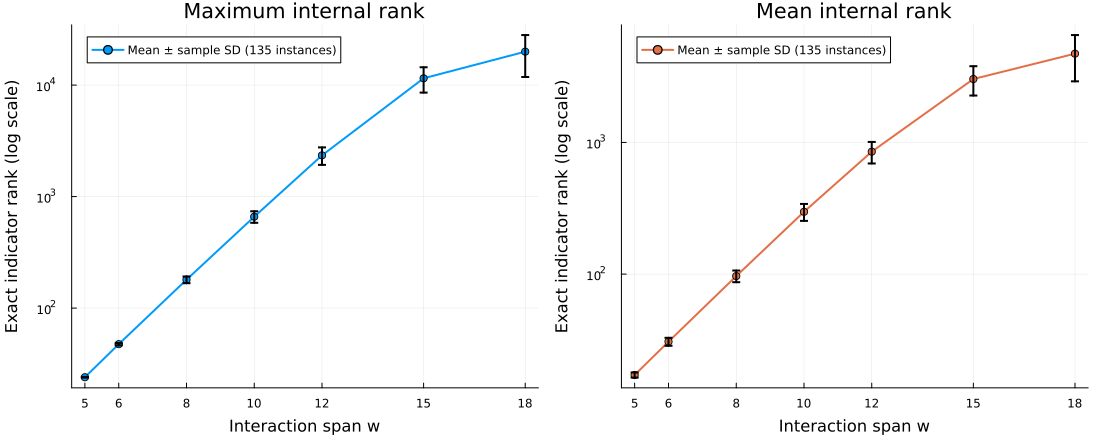

### Pooled summaries (135 tasks per span)

| w | Tasks | Mean max rank ± SD | Mean mean rank ± SD |
|---:|---:|---:|---:|
| 5 | 135 | 24.0 ± 0.2 | 17.2 ± 0.8 |
| 6 | 135 | 47.5 ± 1.2 | 30.7 ± 2.1 |
| 8 | 135 | 179.7 ± 12.5 | 96.6 ± 9.9 |
| 10 | 135 | 660.2 ± 78.2 | 297.3 ± 43.6 |
| 12 | 135 | 2344.2 ± 418.0 | 850.6 ± 158.4 |
| 15 | 135 | 11512.8 ± 2947.6 | 3029.6 ± 761.0 |
| 18 | 135 | 19962.3 ± 8136.1 | 4719.8 ± 1809.9 |


### Full parameter table (15 tasks per row)

SD is across the 15 instances of that group, not across its bonds.

| w | m | n | Tasks | Mean max rank ± SD | Mean mean rank ± SD |
|---:|---:|---:|---:|---:|---:|
| 5 | 18 | 13 | 15 | 24.0 ± 0.0 | 16.5 ± 0.3 |
| 5 | 18 | 14 | 15 | 24.0 ± 0.0 | 17.6 ± 0.2 |
| 5 | 18 | 15 | 15 | 24.0 ± 0.0 | 18.2 ± 0.0 |
| 5 | 19 | 13 | 15 | 23.8 ± 0.4 | 16.2 ± 0.3 |
| 5 | 19 | 14 | 15 | 24.0 ± 0.0 | 17.2 ± 0.2 |
| 5 | 19 | 15 | 15 | 24.0 ± 0.0 | 18.0 ± 0.1 |
| 5 | 20 | 13 | 15 | 23.9 ± 0.3 | 16.1 ± 0.5 |
| 5 | 20 | 14 | 15 | 24.0 ± 0.0 | 17.0 ± 0.3 |
| 5 | 20 | 15 | 15 | 24.0 ± 0.0 | 17.7 ± 0.2 |
| 6 | 18 | 13 | 15 | 47.5 ± 0.8 | 29.4 ± 1.3 |
| 6 | 18 | 14 | 15 | 48.0 ± 0.0 | 31.1 ± 1.1 |
| 6 | 18 | 15 | 15 | 48.0 ± 0.0 | 33.4 ± 0.4 |
| 6 | 19 | 13 | 15 | 46.1 ± 1.7 | 28.0 ± 1.1 |
| 6 | 19 | 14 | 15 | 47.7 ± 0.9 | 31.0 ± 1.1 |
| 6 | 19 | 15 | 15 | 47.9 ± 0.3 | 32.9 ± 0.8 |
| 6 | 20 | 13 | 15 | 46.7 ± 1.7 | 28.0 ± 1.3 |
| 6 | 20 | 14 | 15 | 47.5 ± 1.1 | 30.1 ± 1.2 |
| 6 | 20 | 15 | 15 | 48.0 ± 0.0 | 32.4 ± 0.8 |
| 8 | 18 | 13 | 15 | 175.1 ± 9.2 | 89.3 ± 6.4 |
| 8 | 18 | 14 | 15 | 180.9 ± 11.3 | 97.1 ± 6.4 |
| 8 | 18 | 15 | 15 | 186.9 ± 5.7 | 105.8 ± 4.7 |
| 8 | 19 | 13 | 15 | 169.3 ± 17.5 | 86.9 ± 7.0 |
| 8 | 19 | 14 | 15 | 182.2 ± 7.2 | 97.3 ± 5.1 |
| 8 | 19 | 15 | 15 | 187.7 ± 5.9 | 108.5 ± 4.1 |
| 8 | 20 | 13 | 15 | 169.0 ± 16.7 | 83.9 ± 7.1 |
| 8 | 20 | 14 | 15 | 180.3 ± 10.1 | 96.4 ± 5.0 |
| 8 | 20 | 15 | 15 | 185.9 ± 6.7 | 104.6 ± 4.0 |
| 10 | 18 | 13 | 15 | 633.0 ± 67.4 | 269.4 ± 20.9 |
| 10 | 18 | 14 | 15 | 690.7 ± 48.5 | 305.6 ± 27.8 |
| 10 | 18 | 15 | 15 | 722.9 ± 35.9 | 340.4 ± 21.5 |
| 10 | 19 | 13 | 15 | 614.5 ± 79.8 | 252.2 ± 26.8 |
| 10 | 19 | 14 | 15 | 663.7 ± 53.4 | 302.6 ± 24.7 |
| 10 | 19 | 15 | 15 | 674.3 ± 53.1 | 328.0 ± 24.6 |
| 10 | 20 | 13 | 15 | 537.2 ± 58.6 | 236.6 ± 25.8 |
| 10 | 20 | 14 | 15 | 679.8 ± 59.6 | 297.4 ± 25.6 |
| 10 | 20 | 15 | 15 | 725.8 ± 39.3 | 343.8 ± 29.6 |
| 12 | 18 | 13 | 15 | 2057.5 ± 407.7 | 705.2 ± 113.8 |
| 12 | 18 | 14 | 15 | 2507.7 ± 310.3 | 877.0 ± 106.7 |
| 12 | 18 | 15 | 15 | 2720.2 ± 285.7 | 1019.9 ± 92.8 |
| 12 | 19 | 13 | 15 | 2008.5 ± 311.9 | 712.0 ± 88.8 |
| 12 | 19 | 14 | 15 | 2373.6 ± 349.2 | 843.1 ± 111.2 |
| 12 | 19 | 15 | 15 | 2564.4 ± 261.3 | 974.7 ± 79.4 |
| 12 | 20 | 13 | 15 | 2031.1 ± 342.3 | 701.4 ± 86.4 |
| 12 | 20 | 14 | 15 | 2190.7 ± 389.9 | 812.5 ± 118.6 |
| 12 | 20 | 15 | 15 | 2643.8 ± 321.0 | 1010.0 ± 122.9 |
| 15 | 18 | 13 | 15 | 8315.9 ± 1501.6 | 2135.6 ± 312.0 |
| 15 | 18 | 14 | 15 | 9726.1 ± 1358.3 | 2525.5 ± 264.0 |
| 15 | 18 | 15 | 15 | 11699.8 ± 1131.3 | 3099.6 ± 326.7 |
| 15 | 19 | 13 | 15 | 8906.9 ± 1601.4 | 2290.8 ± 345.5 |
| 15 | 19 | 14 | 15 | 11314.1 ± 1759.1 | 3068.4 ± 413.0 |
| 15 | 19 | 15 | 15 | 13971.9 ± 2431.6 | 3695.0 ± 532.7 |
| 15 | 20 | 13 | 15 | 10436.5 ± 1768.0 | 2721.0 ± 337.0 |
| 15 | 20 | 14 | 15 | 13819.0 ± 2384.5 | 3563.4 ± 403.3 |
| 15 | 20 | 15 | 15 | 15425.1 ± 2419.8 | 4167.4 ± 656.2 |
| 18 | 18 | 13 | 15 | 10939.5 ± 1215.7 | 2608.1 ± 381.5 |
| 18 | 18 | 14 | 15 | 12373.4 ± 1528.6 | 3073.3 ± 369.2 |
| 18 | 18 | 15 | 15 | 15238.7 ± 1115.3 | 3799.6 ± 269.4 |
| 18 | 19 | 13 | 15 | 14414.3 ± 3648.4 | 3484.8 ± 573.0 |
| 18 | 19 | 14 | 15 | 19349.2 ± 1934.4 | 4543.3 ± 499.1 |
| 18 | 19 | 15 | 15 | 23806.8 ± 1883.1 | 5581.8 ± 552.1 |
| 18 | 20 | 13 | 15 | 19916.5 ± 3220.2 | 4564.0 ± 587.2 |
| 18 | 20 | 14 | 15 | 28475.1 ± 5384.3 | 6660.2 ± 1032.7 |
| 18 | 20 | 15 | 15 | 35147.5 ± 4670.1 | 8163.3 ± 942.0 |


## Reproduce

From the project root, run `julia --project=. --threads=1 scripts/check_training_gradient.jl` for the derivative audit and `julia --project=. --threads=1 scripts/check_PartitionLocality.jl` for the exact-generator, legacy-input and paired smoke checks. Generate or revalidate the new inputs with `julia --project=. --threads=1 scripts/generate_PartitionLocalityGrid.jl`.

The full tables are in `examples/partition_locality_grid/rank_groups.csv` and `rank_pooled.csv`, with unrounded values. The manifest and per-instance table are under `data/set_partitioning/locality_grid_v1/`. The PNG/PDF figures are generated by Julia/Plots. The following cell regenerates the structural report from the saved manifest; it does not run optimization.


In [ ]:
project_root = isfile("Project.toml") ? pwd() : dirname(pwd())
include(joinpath(project_root, "scripts", "report_PartitionLocalityGrid.jl"))